In [2]:
import torch, torch.nn as nn
import torch.nn.functional as F
import math, copy
print(torch.__version__)


2.14.1+cpu


**RULES**

- L1. Same data, same split, same scaling as Day 16. The test set is not used today.

- L2. Base model = C (64 -> 128 -> 64 -> 10, 17,226 parameters), Adam lr = 0.01, 30 epochs, seed 42.

- L3. Change ONE thing at a time. Build the model with mk(...) or mkd(...) (which set the seed) right
before each training run, so the results are reproducible.

- L4. Metric: validation loss at the model's BEST epoch (lowest over all epochs). Report validation accuracy
next to it.

- L5. A change is an IMPROVEMENT only if its best validation loss is more than 10% lower than the baseline's
(baseline 0.0731, so below 0.0658). Smaller differences are treated as noise.

- L6. Before each part, write one line: "I expect ..., because ...".
Note on reproducibility: dropout and augmentation use random numbers, so they can differ across PyTorch
versions more than plain training does. If your numbers differ slightly, the DIRECTION and the rough size
of each effect are what counts.


In [3]:
import copy, os
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
import torch.nn.functional as F

In [4]:
#DATA
d = load_digits()
X, y = d.data, d.target
print(X.shape, X.min(), X.max())
print(np.bincount(y))

(1797, 64) 0.0 16.0
[178 182 177 183 181 182 181 179 174 180]


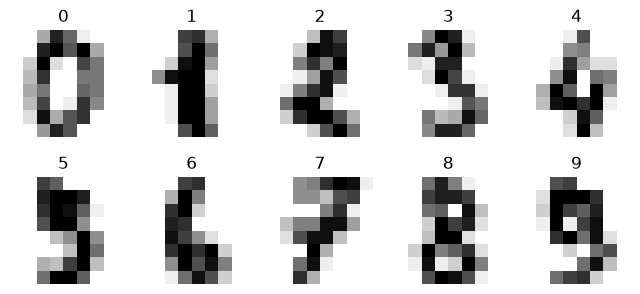

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(8, 3.5))
for ax, img, lab in zip(axes.ravel(), d.images[:10], d.target[:10]):
  ax.imshow(img, cmap="gray_r")
  ax.set_title(lab)
  ax.axis("off")
plt.show()

In [6]:
X_tv, X_te, y_tv, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
Xtr, Xval, ytr, yval = train_test_split(X_tv, y_tv, test_size=0.25, random_state=42, stratify=y_tv)

Xtr, Xval, X_te = Xtr / 16.0, Xval / 16.0, X_te / 16.0

print(Xtr.shape, Xval.shape, X_te.shape)
print(Xtr.max(), round(Xtr.mean(), 4))
print("majority baseline (val):", round(np.bincount(yval).max() / len(yval), 4))

(1077, 64) (360, 64) (360, 64)
1.0 0.3065
majority baseline (val): 0.1028


In [7]:
class DigitDataset(Dataset):
  def __init__(self, X, y):
    self.X = torch.tensor(X, dtype=torch.float32)
    self.y = torch.tensor(y, dtype=torch.long)

  def __len__(self):
    return len(self.y)

  def __getitem__(self, idx):
    return self.X[idx], self.y[idx]

In [8]:
train_ds, val_ds, test_ds = DigitDataset(Xtr, ytr), DigitDataset(Xval, yval), DigitDataset(X_te, y_te)
print(len(train_ds), len(val_ds), len(test_ds))
print(train_ds[0][0].shape, train_ds[0][0].dtype, train_ds[0][1], train_ds[0][1].dtype)

1077 360 360
torch.Size([64]) torch.float32 tensor(3) torch.int64


In [9]:
def new_train_loader():
  return DataLoader(train_ds, batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(42))

val_loader = DataLoader(val_ds, batch_size=256)

xb, yb = next(iter(new_train_loader()))
print(xb.shape, yb.shape, xb.dtype, yb.dtype)
print(len(new_train_loader()), len(val_loader))
print("rows in the last train batch:", len(train_ds) - (len(new_train_loader()) - 1) * 64)

torch.Size([64, 64]) torch.Size([64]) torch.float32 torch.int64
17 2
rows in the last train batch: 53


In [10]:
loss_fn = nn.CrossEntropyLoss()

def run_epoch(model, loader, opt=None):
  train = opt is not None
  model.train() if train else model.eval()
  tot, correct, n = 0.0, 0, 0
  with torch.set_grad_enabled(train):
    for xb, yb in loader:
      logits = model(xb)
      loss = loss_fn(logits, yb)
      if train:
        loss.backward()
        opt.step()
        opt.zero_grad()
      tot += loss.item() * len(yb)
      correct += (logits.argmax(dim=1) == yb).sum().item()
      n += len(yb)
  return tot / n, correct / n

def mk(kind):
  torch.manual_seed(42)
  if kind == "A": return nn.Linear(64, 10)
  if kind == "B": return nn.Sequential(nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 10))
  return nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 10))

In [11]:
def train_model2(model, opt, epochs, loader=None, patience=None, sched=None):
  if loader is None:
    loader = new_train_loader()
  h = {"tl": [], "ta": [], "vl": [], "va": [], "lr": []}
  best = {"vl": float("inf")}
  bad, stopped = 0, None
  for e in range(1, epochs + 1):
    tl_, ta_ = run_epoch(model, loader, opt)
    vl_, va_ = run_epoch(model, val_loader)
    h["tl"].append(tl_)
    h["ta"].append(ta_)
    h["vl"].append(vl_)
    h["va"].append(va_)
    h["lr"].append(opt.param_groups[0]["lr"])
    if sched is not None:
      if isinstance(sched, torch.optim.lr_scheduler.ReduceLROnPlateau):
        sched.step(vl_)
      else:
        sched.step()
    if vl_ < best["vl"]:
      best = {"vl": vl_, "va": va_, "epoch": e, "state": copy.deepcopy(model.state_dict())}
      bad = 0
    else:
      bad += 1
      if patience is not None and bad >= patience:
        stopped = e
        break
  return h, best, stopped

In [12]:
def report(name, h, best, stopped=None):
  print(name, "| best epoch", best["epoch"], "val loss", round(best["vl"], 4),
        "val acc", round(best["va"], 4), "| last epoch", len(h["tl"]), "train acc", round(h["ta"][-1], 4), "val loss", round(h["vl"][-1], 4),
        "| stopped", stopped)

def mkd(p):
  torch.manual_seed(42)
  return nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Dropout(p), nn.Linear(128, 64), nn.ReLU(), nn.Dropout(p), nn.Linear(64, 10))

In [13]:
m = mk("C")
h, best, stopped = train_model2(m, torch.optim.Adam(m.parameters(), lr=0.01), 30)
report("0 baseline C", h, best, stopped)

0 baseline C | best epoch 19 val loss 0.0731 val acc 0.9778 | last epoch 30 train acc 1.0 val loss 0.0834 | stopped None


- The baseline's last-epoch train accuracy is 1.0 and its validation loss at epoch 30 is higher than at epoch 19. Name the problem and the first symptom.
  * The model has started to overfit due to have more capacity to memorize the training set instead of learning general patterns. The first symptom is, train keeps improving while validation turns the other way and the val loss at its last epoch 30 (0.0834) higher than its best epoch 19 (0.0731). Since, the patience=None is loop never call the break and it forces the model train through 30 epochs.

In [14]:
#PART 1. DROPOUT
for p in (0.2, 0.3, 0.5):
  m = mkd(p)
  h, best, stopped = train_model2(m, torch.optim.Adam(m.parameters(), lr=0.01), 30)
  report(f"1 dropout {p}", h, best, stopped)

1 dropout 0.2 | best epoch 19 val loss 0.0714 val acc 0.9722 | last epoch 30 train acc 0.9907 val loss 0.0977 | stopped None
1 dropout 0.3 | best epoch 28 val loss 0.064 val acc 0.9861 | last epoch 30 train acc 0.9759 val loss 0.0986 | stopped None
1 dropout 0.5 | best epoch 23 val loss 0.0967 val acc 0.9694 | last epoch 30 train acc 0.9443 val loss 0.1238 | stopped None


- Apply rule L5 to each p (threshold 0.0658): which ones are improvements?
  * threshold 0.3 have the improve since the val loss decrease more than 10% from the baseline (0.0731) which the gap is (0.0731 - 0.045 = 0.0281).

- Look at the train accuracy column: 0.9963, 0.9777, 0.9443. What does dropout do to the training
accuracy, and why is that not a bad sign here?
  * The training accuracy decreasing since the dropout rate is increasing because dropout randomly deactivates a percentage of neurons during each forward pass of training. and it is not a bad sign because train accuracy is measured with dropout on. The network is no longer memorising noise.

- p = 0.5 is worse than 0.3. Is that overfitting or underfitting? Explain with the train accuracy.
  * p = 0.5 is underfitting: dropping half the units each pass makes the model too noisy to fit even the training rows (train accuracy 0.9443), and its best validation loss (0.0967) is worse than the baseline’s 0.0731.


In [15]:
#PART 2. WEIGHT DECAY (AdamW)
for wd in (0.01, 0.1, 1.0):
  m = mk("C")
  opt = torch.optim.AdamW(m.parameters(), lr=0.01, weight_decay=wd)
  h, best, stopped = train_model2(m, opt, 30)
  report(f"2 AdamW wdd {wd}", h, best, stopped)

2 AdamW wdd 0.01 | best epoch 30 val loss 0.0681 val acc 0.9833 | last epoch 30 train acc 1.0 val loss 0.0681 | stopped None
2 AdamW wdd 0.1 | best epoch 22 val loss 0.0552 val acc 0.9861 | last epoch 30 train acc 0.9972 val loss 0.0903 | stopped None
2 AdamW wdd 1.0 | best epoch 28 val loss 0.1385 val acc 0.975 | last epoch 30 train acc 0.9684 val loss 0.1654 | stopped None


- Apply L5 to each: which weight decay values are improvements?
  * weight decay at 0.1 does the improvement with val loss(0.0552).

- wd = 0.01 reaches 0.0681 at the LAST epoch. Is it an improvement under L5, and why is "best epoch 30"
a warning sign that the run was cut short?
  * No, finishing with a "best epoch 30" is a clear warning sign that the run was cut short because the validation loss curve is still actively decreasing and has not yet plateaued or bottomed out.

- wd = 1.0 is clearly worse. Which symptom (look at train accuracy) tells you it is underfitting?
  * wd = 1.0 underfits: its train accuracy (0.9666) is lower than at 0.01 and 0.1 (1.0 and 0.9972), and its best validation loss (0.1361) is worse than the baseline’s 0.0731. The penalty is so strong that the weights can’t grow large enough to fit even the training rows.

In [16]:
#PART 3. EARLY STOPPING
for pat in (5, 8):
  m = mk("C")
  h, best, stopped = train_model2(m, torch.optim.Adam(m.parameters(), lr=0.01), 30, patience=pat)
  report(f"3 early stopping {pat}", h, best, stopped)

3 early stopping 5 | best epoch 13 val loss 0.0835 val acc 0.9722 | last epoch 18 train acc 0.9935 val loss 0.0933 | stopped 18
3 early stopping 8 | best epoch 19 val loss 0.0731 val acc 0.9778 | last epoch 27 train acc 1.0 val loss 0.0825 | stopped 27


- Patience 5 stopped at epoch 18 and kept epoch 13 (0.0835). Patience 8 kept epoch 19 (0.0731). Why did
patience 5 do worse, and what does your answer to H3 (patience 3 vs 4) have to do with it?
  * Patience 5 did worse because it got earl stop at epoch 18 because the bad reached 5. Patience 5 stopped at epoch 18 after five epochs with no new best, and restored epoch 13 (0.0835). But the validation loss reached its real low of 0.0731 at epoch 19, one epoch after the stop. The curve is jagged, so a short patience gives up before a later improvement. That is the same as H3: patience 3 stopped at epoch 7 and missed the 0.50 at epoch 8.

- Early stopping did not beat the baseline's best (0.0731). So what did it give you? (Think: epochs
saved, and the weights you get back.)
  * Early stop, stops training before things get worse and hands back the best weights. It didn’t beat 0.0731 because your baseline already restores its best epoch (the deepcopy in train_model2). and does gives the best epoch with lowest validation loss. It also saves time by stop earlier and gives the best epoch.

- Why does the function return the weights from the best epoch and not the last epoch?
  * Because the model does takes a clean snapshot only when the validation loss improves by .deepcopy() and the function does not only looks at the last epoch. The best epoch will not update, and returns the weight from best epoch.

In [17]:
#PART 4. LEARNING-RATE SCHEDULES
m = mk("C")
opt = torch.optim.Adam(m.parameters(), lr=0.01)
sched = torch.optim.lr_scheduler.StepLR(opt, step_size=10, gamma=0.3)
h, best, stopped = train_model2(m, opt, 30, sched=sched)
report("4 StepLR 10, 0.3", h, best, stopped)
print([h["lr"][i - 1] for i in (1, 10, 11, 20, 21, 30)])

4 StepLR 10, 0.3 | best epoch 18 val loss 0.0942 val acc 0.9667 | last epoch 30 train acc 1.0 val loss 0.0945 | stopped None
[0.01, 0.01, 0.003, 0.003, 0.0009, 0.0009]


In [18]:
m = mk("C")
opt = torch.optim.Adam(m.parameters(), lr=0.01)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
h, best, stopped = train_model2(m, opt, 30, sched=sched)
report("4 reduceLROnPlateau 0.5, 2", h, best, stopped)
print(sorted(set(h["lr"]), reverse=True))

4 reduceLROnPlateau 0.5, 2 | best epoch 21 val loss 0.0796 val acc 0.9778 | last epoch 30 train acc 1.0 val loss 0.0807 | stopped None
[0.01, 0.005, 0.0025, 0.00125, 0.000625]


- Neither beats 0.0658, so neither is an L5 improvement. Compare the LAST-epoch validation loss with the
baseline's last epoch (0.0834): what did the schedules do to the end of training?
  * In StepLR the validation loss increase and in ReduceLROnPlateau the validation loss decreased to 0.0807, just beats by 0.0027 which is a tie. The last epoch is close to their own best (0.0807 vs 0.0796 and 0.0945 vs 0.0942), while the baseline’s last epoch (0.0834) sits well above its best (0.0731). The schedules calmed the end of training.

- Why did StepLR with gamma 0.3 end worse than the baseline's best (0.0942 vs 0.0731)?
  * Because StepLR cuts down the learning rate by 70% everytime it hits the step_size. the learning rate dropped to 0.003 at epoch 11, while the baseline was still improving at 0.01 up to epoch 19. The model settled early in a worse place.

- So what is a learning-rate schedule good for here? One sentence.
  * Here a learning-rate schedule mainly makes the end of training calmer, so the last epoch lands close to the best epoch.


In [19]:
#PART 5. DATA AUGMENTATION (one good, one bad)
class AugDataset(Dataset):
  def __init__(self, X, y, mode="none", p=0.5, std=0.1):
    self.X = torch.tensor(X, dtype=torch.float32)
    self.y = torch.tensor(y, dtype=torch.long)
    self.mode, self.p, self.std = mode, p, std

  def __len__(self):
    return len(self.y)

  def __getitem__(self, idx):
    x = self.X[idx]
    if self.mode == "noise":
      x = (x + self.std * torch.randn(64)).clamp(0, 1)
    elif self.mode == "shift" and torch.rand(1).item() < self.p:
      dx, dy = torch.randint(-1, 2, (2, )).tolist()
      pad = F.pad(x.reshape(1, 8, 8), (1, 1, 1, 1))[0]
      x = pad[1 + dy:9 + dy, 1 + dx:9 + dx].reshape(64)
    elif self.mode == "roll":
      dx, dy = torch.randint(-1, 2, (2, )).tolist()
      x = torch.roll(x.reshape(8, 8), shifts=(dy, dx), dims=(0, 1)).reshape(64)
    return x, self.y[idx]

In [20]:
def aug_loader(mode, **kw):
  return DataLoader(AugDataset(Xtr, ytr, mode, **kw), batch_size=64, shuffle=True,
                    generator=torch.Generator().manual_seed(42))

for name, ld in (("noise 0.05", aug_loader("noise", std=0.05)),
                     ("noise 0.1", aug_loader("noise", std=0.1)),
                     ("noise 0.2", aug_loader("noise", std=0.2)),
                     ("shift p=0.2", aug_loader("shift", p=0.2)),
                     ("shift p=0.5", aug_loader("shift", p=0.5)),
                     ("roll (wrap)", aug_loader("roll"))):
    m = mk("C")
    h, best, stopped = train_model2(m, torch.optim.Adam(m.parameters(), lr=0.01), 30, loader=ld)
    report("5 " + name, h, best, stopped)


5 noise 0.05 | best epoch 28 val loss 0.0357 val acc 0.9861 | last epoch 30 train acc 0.9991 val loss 0.0481 | stopped None
5 noise 0.1 | best epoch 30 val loss 0.0388 val acc 0.9861 | last epoch 30 train acc 0.9889 val loss 0.0388 | stopped None
5 noise 0.2 | best epoch 30 val loss 0.0412 val acc 0.9778 | last epoch 30 train acc 0.9638 val loss 0.0412 | stopped None
5 shift p=0.2 | best epoch 16 val loss 0.0535 val acc 0.9833 | last epoch 30 train acc 0.9712 val loss 0.114 | stopped None
5 shift p=0.5 | best epoch 29 val loss 0.0558 val acc 0.9833 | last epoch 30 train acc 0.9629 val loss 0.0763 | stopped None
5 roll (wrap) | best epoch 26 val loss 0.187 val acc 0.9417 | last epoch 30 train acc 0.9424 val loss 0.2782 | stopped None


- Noise 0.1 gives the lowest validation loss of the whole lab so far (0.0388). Apply L5. What does its
train accuracy (0.9889, not 1.0) say about memorising?
  * It does beats the baseline's val loss by 0.0343 and in train accuracy it achieves a bit lower (0.9889) than 1.0 which each epoch shows slightly different noisy copies, so the model cannot memorise the exact pixel values, and its train accuracy stays at 0.9889. By apply L5 i would choose this model.

- Noise runs have "best epoch 30". What does that suggest about training longer? (Optional bonus: rerun
noise 0.1 with 60 epochs and report what you see. I have not run it, so I do not know the answer.)
  *  it suggests that the model has not finished learning yet, and you should train it for longer (increase the total number of epochs). At epoch 60 the model achieves thhe lowest val loss (0.031) at epoch 58.

- The roll version made things MUCH worse (validation loss 0.1771, validation accuracy 0.9389). Use your
H6 answer: why does a 1-pixel wrap-around shift damage an 8x8 digit so badly?
  * Because the augmentation method introduced destructive noise that broke the core spatial rules of your dataset. Roll wraps ink from one edge to the opposite edge, so a digit that fills an 8×8 frame gets part of itself moved to the other side. The label still says “7”, but the image no longer looks like a clean 7, so it is almost label noise. Evidence: train accuracy only 0.922, and validation loss 0.3349 at the last epoch.

- State in one sentence the rule for a good augmentation (it must ... the label).
  * The rule for good aumentation, it must alter the input data while preserving the meaning of the label.


In [21]:
#PART 6. COMBINATIONS (do the regularisers add up?)

# 6a noise 0.1 + dropout 0.3
m = mkd(0.3)
h, best, stopped = train_model2(m, torch.optim.Adam(m.parameters(), lr=0.01), 30, loader=aug_loader("noise", std=0.1))
report("6a noise0.1 + dropout0.3", h, best, stopped)

6a noise0.1 + dropout0.3 | best epoch 24 val loss 0.0451 val acc 0.9833 | last epoch 30 train acc 0.9564 val loss 0.0717 | stopped None


In [22]:
# 6b noise 0.1 + AdamW 0.1
m = mk("C")
h, best, stopped =  train_model2(m, torch.optim.AdamW(m.parameters(), lr=0.01, weight_decay=0.1), 30, loader=aug_loader("noise", std=0.1))
report("6b noise0.1 + AdamW0.1", h, best, stopped)

6b noise0.1 + AdamW0.1 | best epoch 30 val loss 0.05 val acc 0.9889 | last epoch 30 train acc 0.9889 val loss 0.05 | stopped None


In [23]:
# 6c dropout 0.3 + AdamW 0.1
m = mkd(0.3)
h, best, stopped =  train_model2(m, torch.optim.AdamW(m.parameters(), lr=0.01, weight_decay=0.1), 30)
report("6c dropout0.3 + AdamW0.1", h, best, stopped)

6c dropout0.3 + AdamW0.1 | best epoch 27 val loss 0.0569 val acc 0.9778 | last epoch 30 train acc 0.9749 val loss 0.1003 | stopped None


In [24]:
# 6d the "everything" run: noise 0.1 + dropout 0.3 + ReduceLROnPlateau + patience 8, up to 40 epochs
m = mkd(0.3)
opt = torch.optim.Adam(m.parameters(), lr=0.01)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
h, best, stopped = train_model2(m, opt, 40, loader=aug_loader("noise", std=0.1), patience=8, sched=sched)
report("6d everything", h, best, stopped)

6d everything | best epoch 22 val loss 0.0479 val acc 0.9861 | last epoch 30 train acc 0.9786 val loss 0.0581 | stopped 30


- Compare each combination with the best single change (noise 0.1 at 0.0388, dropout 0.3 at 0.045).
Did any combination beat the best single one?
  * Nothing beats the noise 0.1 at 0.0388 dropout 0.3 at 0.045
Run	| Best val loss |	noise 0.1 alone (0.0388)	| dropout 0.3 alone (0.0450)
6a noise + dropout	0.0451	worse	same (0.0451 vs 0.0450)
6b noise + AdamW	0.0500	worse	worse
6c dropout + AdamW	0.0553	worse	worse
6d everything	0.0479	worse	worse

- "Regularisers add up" sounds natural. Your table says otherwise. Give one reason (hint: they all
fight the same problem, so after the first one removes most of the memorising, the others have less
left to remove, and together they can start to underfit).
  * Each regulariser attacks the same problem, memorising. Once noise 0.1 removed most of it, adding dropout, weight decay or a scheduler had little left to fix, and sometimes made the model fit the training rows a bit worse (6a’s train accuracy 0.9564). So none of the combinations beat noise 0.1 alone (0.0388).

- Run 6d stopped at epoch 30 with patience 8. Check the stop epoch: why did it stop there and not run
to 40?
  * The best epoch was 22, and the patience is 8. Epochs 23 through 30 are eight epochs in a row with no new best, so the counter bad reached 8 at epoch 30 and the break fired. The run could have gone to 40, but patience ended it. In general: stop epoch = best epoch + patience, if there is no improvement after the best.

In [25]:
#PART 7. DECISION TABLE (values copied from the outputs above)
base = 0.0731
rows = [
  ("0 baseline C", 0.0731, 0.9778),
  ("1 dropout 0.2", 0.0714, 0.9722),
  ("1 dropout 0.3", 0.045, 0.9861),
  ("1 dropout 0.5", 0.0967, 0.9694),
  ("2 AdamW wd 0.01", 0.0681, 0.9833),
  ("2 AdamW wd 0.1", 0.0552, 0.9861),
  ("2 AdamW wd 1.0", 0.1361, 0.9722),
  ("3 early stopping 5", 0.0835, 0.9722),
  ("3 early stopping 8", 0.0731, 0.9778),
  ("4 StepLR 10, 0.3", 0.0942, 0.9667),
  ("4 ReduceLROnPlateau 0.5, 2", 0.0796, 0.9778),
  ("5 noise 0.05", 0.0397, 0.9833),
  ("5 noise 0.1", 0.0388, 0.9861),
  ("5 noise 0.2", 0.0412, 0.9778),
  ("5 shift p=0.2", 0.0535, 0.9833),
  ("5 shift p=0.5", 0.0534, 0.9833),
  ("5 roll (wrap)", 0.1771, 0.9389),
  ("6a noise 0.1 + dropout 0.3", 0.0451, 0.9833),
  ("6b noise 0.1 + AdamW 0.1", 0.05, 0.9889),
  ("6c dropout 0.3 + AdamW 0.1", 0.0553, 0.9778),
  ("6d everything", 0.0479, 0.9861),
]
print(f"{'experiment':30s}{'best val loss':>14s}{'best val acc':>14s}{'vs baseline':>13s}   L5")
for name, vl, va in rows:
  change = (base - vl) / base * 100
  print(f"{name:30s}{vl:14.4f}{va:14.4f}{change:12.1f}%   {'YES' if vl < base * 0.9 else 'no'}")


experiment                     best val loss  best val acc  vs baseline   L5
0 baseline C                          0.0731        0.9778         0.0%   no
1 dropout 0.2                         0.0714        0.9722         2.3%   no
1 dropout 0.3                         0.0450        0.9861        38.4%   YES
1 dropout 0.5                         0.0967        0.9694       -32.3%   no
2 AdamW wd 0.01                       0.0681        0.9833         6.8%   no
2 AdamW wd 0.1                        0.0552        0.9861        24.5%   YES
2 AdamW wd 1.0                        0.1361        0.9722       -86.2%   no
3 early stopping 5                    0.0835        0.9722       -14.2%   no
3 early stopping 8                    0.0731        0.9778         0.0%   no
4 StepLR 10, 0.3                      0.0942        0.9667       -28.9%   no
4 ReduceLROnPlateau 0.5, 2            0.0796        0.9778        -8.9%   no
5 noise 0.05                          0.0397        0.9833        45.7%   

**PART 7. THE DECISION TABLE**

| Experiment | Best val loss | Best val acc | vs baseline | L5 improvement? (below 0.0658) |
|---|---|---|---|---|
| 0 baseline C | 0.0731 | 0.9778 | 0% lower | no |
| 1 dropout 0.2 | 0.0714 | 0.9722 | 2% lower | no |
| 1 dropout 0.3 | 0.0450 | 0.9861 | 38% lower | **YES** |
| 1 dropout 0.5 | 0.0967 | 0.9694 | 32% higher | no |
| 2 AdamW wd 0.01 | 0.0681 | 0.9833 | 7% lower | no |
| 2 AdamW wd 0.1 | 0.0552 | 0.9861 | 24% lower | **YES** |
| 2 AdamW wd 1.0 | 0.1361 | 0.9722 | 86% higher | no |
| 3 early stopping 5 | 0.0835 | 0.9722 | 14% higher | no |
| 3 early stopping 8 | 0.0731 | 0.9778 | 0% lower | no |
| 4 StepLR 10, 0.3 | 0.0942 | 0.9667 | 29% higher | no |
| 4 ReduceLROnPlateau 0.5, 2 | 0.0796 | 0.9778 | 9% higher | no |
| 5 noise 0.05 | 0.0397 | 0.9833 | 46% lower | **YES** |
| 5 noise 0.1 | 0.0388 | 0.9861 | 47% lower | **YES** |
| 5 noise 0.2 | 0.0412 | 0.9778 | 44% lower | **YES** |
| 5 shift p=0.2 | 0.0535 | 0.9833 | 27% lower | **YES** |
| 5 shift p=0.5 | 0.0534 | 0.9833 | 27% lower | **YES** |
| 5 roll (wrap) | 0.1771 | 0.9389 | 142% higher | no |
| 6a noise 0.1 + dropout 0.3 | 0.0451 | 0.9833 | 38% lower | **YES** |
| 6b noise 0.1 + AdamW 0.1 | 0.0500 | 0.9889 | 32% lower | **YES** |
| 6c dropout 0.3 + AdamW 0.1 | 0.0553 | 0.9778 | 24% lower | **YES** |
| 6d everything | 0.0479 | 0.9861 | 34% lower | **YES** |

L5 threshold = 0.0731 x 0.9 = 0.0658. Improvements: dropout 0.3, AdamW 0.1, noise 0.05 / 0.1 / 0.2, shift p=0.2 / p=0.5 and all four combinations. Not improvements: dropout 0.2 and 0.5, AdamW 0.01 and 1.0, early stopping 5 and 8, StepLR, ReduceLROnPlateau and roll.

- Which single change wins, and by how much over the baseline?
  * Gaussian noise with std 0.1 wins: best validation loss 0.0388 against the baseline's 0.0731, which is 47% lower, with validation accuracy 0.9861. Noise 0.05 (0.0397) and 0.2 (0.0412) are almost the same, so the whole noise 0.05 to 0.2 range works, and dropout 0.3 (0.0450, 38% lower) is a close second. Two cautions: the noise runs have "best epoch 30" (still improving when stopped), and each number comes from one run on 360 validation images, so small gaps like 0.0388 against 0.0397 are noise.

- How does the winner compare with Day 16's chosen model B (best val loss 0.0873, val acc 0.975)? Was model C a bad idea on Day 16, or just unregularised?
  * The winner's validation loss is 56% lower than B's (0.0388 against 0.0873) and its accuracy is higher by 0.0111, which is 4 validation images. So model C was not a bad idea on Day 16, it was just unregularised: on Day 16 it memorised the 1,077 training rows (train accuracy 1.0), which cancelled the benefit of its extra capacity, and R4 correctly chose the simpler B. Once the memorising is controlled, the bigger network is clearly better. The winner is only a candidate: it was chosen on the validation set and the test set is still closed.

- Name the two experiments that HURT, with a one-sentence reason each.
  * Roll (wrap) was the worst (0.1771, 142% higher than the baseline): it moves ink from one edge of the 8x8 image to the opposite edge, so the picture no longer matches its label, which is almost label noise. AdamW with wd = 1.0 was second (0.1361, 86% higher): the penalty is so strong that the weights cannot grow large enough to fit even the training rows (train accuracy 0.9666), so it underfits. Dropout 0.5 also hurt (0.0967, 32% higher) for the same underfitting reason.


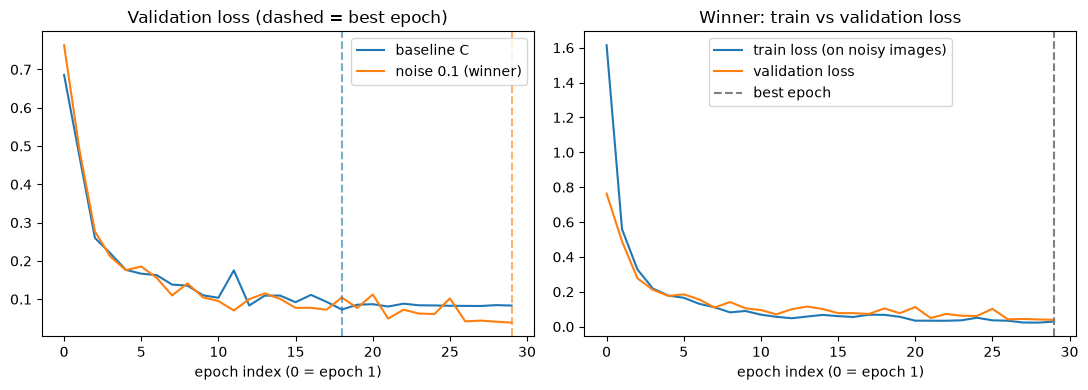

baseline best epoch 19 0.0731 | winner best epoch 30 0.0388


In [26]:
#PART 8. PLOT: baseline vs winner (this cell re-trains both, about half a minute)
m = mk("C")
base_h, base_best, _ = train_model2(m, torch.optim.Adam(m.parameters(), lr=0.01), 30)
m = mk("C")
win_h, win_best, _ = train_model2(m, torch.optim.Adam(m.parameters(), lr=0.01), 30, loader=aug_loader("noise", std=0.1))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# left: validation loss of the baseline and of the winner
ax[0].plot(base_h["vl"], label="baseline C")
ax[0].plot(win_h["vl"], label="noise 0.1 (winner)")
ax[0].axvline(base_best["epoch"] - 1, color="C0", linestyle="--", alpha=0.6)
ax[0].axvline(win_best["epoch"] - 1, color="C1", linestyle="--", alpha=0.6)
ax[0].set_title("Validation loss (dashed = best epoch)")
ax[0].set_xlabel("epoch index (0 = epoch 1)")
ax[0].legend()

# right: train loss and validation loss of the winner
ax[1].plot(win_h["tl"], label="train loss (on noisy images)")
ax[1].plot(win_h["vl"], label="validation loss")
ax[1].axvline(win_best["epoch"] - 1, color="gray", linestyle="--", label="best epoch")
ax[1].set_title("Winner: train vs validation loss")
ax[1].set_xlabel("epoch index (0 = epoch 1)")
ax[1].legend()

fig.tight_layout()
plt.show()
print("baseline best epoch", base_best["epoch"], round(base_best["vl"], 4), "| winner best epoch", win_best["epoch"], round(win_best["vl"], 4))


**PART 8. CONCLUSION AND NOTES**

- **Overfitting in a network is not the same as in a forest.** Model C has 17,226 parameters for 1,077 rows (0.063 rows per parameter), so it can memorise the training set (train accuracy 1.0, train loss 0.0006). A forest has one main knob (tree depth). A network overfits over time (the same model gets worse after epoch 19), has many knobs (depth, width, epochs, learning rate, regularisers), and is judged by loss curves, not one final score. The validation set also decides when to stop, so the best-epoch number is a little optimistic.

- **What each tool does.** Dropout randomly switches off units during training (and is off in `model.eval()`). Weight decay shrinks the weights; with Adam use AdamW, because Adam's step normalisation cancels an L2 penalty added to the gradient (the H2 numbers). Early stopping stops after `patience` epochs without a new best and returns the best weights. A learning-rate schedule lowers the learning rate to calm the end of training. Augmentation adds label-preserving variations of the training images, never of validation or test.

- **What helped (best val loss against the baseline's 0.0731):** noise 0.1 at 0.0388 (47% lower), dropout 0.3 at 0.0450 (38%), shift at 0.0535 (27%), AdamW 0.1 at 0.0552 (24%). **No gain:** dropout 0.2, AdamW 0.01, early stopping (it saved epochs but cannot beat a baseline that already restores its best epoch) and both schedulers (calmer end, no better best). **Hurt:** roll (0.1771), AdamW 1.0 (0.1361) and dropout 0.5 (0.0967).

- **A good augmentation must keep the label true.** Roll wraps ink to the opposite edge of an 8x8 image, which invents a picture that no longer matches its label. My own bug taught the same lesson from the other side: `torch.randn` instead of `torch.rand` in the shift condition silently shifted 58% and 69% of the images instead of 20% and 50%, and only the mismatch with the checkpoint revealed it.

- **Regularisers did not add up.** The four combinations (0.0451 to 0.0553) were no better than noise 0.1 alone (0.0388): they attack the same problem, memorising, so after the first one the others have little left to fix, and 6a's train accuracy even dropped to 0.9564.

- **Be careful with one run on 360 images.** One validation image is 0.0028 accuracy, and the curves are jagged: the 60-epoch noise run reached 0.031 at epoch 58 but 0.0909 at epoch 60. That is why rule L5 asks for a 10% gain, and why the test set stayed closed today (it was already opened on Day 16, and opening it again would turn it into a second validation set).

- **Next:** the noise run was still improving at epoch 30, so try more epochs together with early stopping (patience 8 to 10) and ReduceLROnPlateau. A CNN on Day 18 should do better still, because it keeps the neighbourhood structure of the pixels that a flat 64-number input throws away.

- **H7 check:** my guess in H7 was ______; the results say that augmentation with noise (a change to the data) helped most, with dropout (a change to the model) second.
